# **Project 30:** *Analyzis of Wordnet consistency in Synonymy and Antonymy relationships*
**Authors:**
* Miro Lammi
* Eemeli Kyröläinen (2309218), ekyrolai23@student.oulu.fi

#### Requirements (*Python 3.12*):
`pip install nltk` <br>
`pip install pandas` <br>
`pip install jupyter` <br>
`pip install matplotlib` <br>
`pip install numpy` <br>

or run: <br>
`pip install -r requirements.txt`

## Imports and initialization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import defaultdict
from itertools import combinations
from nltk.corpus import wordnet as wn
from sympy.physics.units import percent

POS_TAGS = [wn.NOUN, wn.VERB]
METHODS = ["path", "wup"]


def similarity(s1, s2, method="path"):
    if method not in METHODS:
        raise ValueError("[ERROR]: Invalid method! method must be one of {}".format(METHODS))
    if method == "path":
        return wn.synset(s1).path_similarity(wn.synset(s2))
    return wn.synset(s1).wup_similarity(wn.synset(s2))

## 1. Getting synonyms and antonyms for each verb and noun in WordNet lexical database and calculating path similarity for each pair.

In [2]:
def get_all_pairs(pos):
    pairs = set()

    for synset in wn.all_synsets(pos):
        lemmas = synset.lemmas()

        for l1, l2 in combinations(lemmas, 2):
            w1, w2 = sorted([l1.name(), l2.name()])

            if w1 != w2:
                pairs.add((pos, "synonym", w1, w2, synset.name(), synset.name()))

        for lemma in lemmas:
            for antonym in lemma.antonyms():
                a_synset = antonym.synset()
                if a_synset.pos() != pos:
                    continue

                a, b = sorted([(lemma.name(), synset.name()),
                               (antonym.name(), a_synset.name())])

                if a[0] != b[0]:
                    pairs.add((pos, "antonym", a[0], b[0], a[1], b[1]))
    return pairs

results = []

for pos in POS_TAGS:
    pairs = get_all_pairs(pos)

    for p, rel, w1, w2, s1, s2 in pairs:
        sim = similarity(s1, s2, "wup")
        results.append({
            'pos': p,
            'relation': rel,
            'word1': w1,
            'word2': w2,
            'similarity': sim
        })

DATAFRAME = pd.DataFrame(results)

statistics = (DATAFRAME.groupby(["pos", "relation"])["similarity"].agg(["count", "min", "max", "mean"]))
display(statistics)

count       min       max      mean
pos relation                                      
n   antonym     1076  0.125000  0.933333  0.752211
    synonym   107469  0.727273  1.000000  0.996726
v   antonym      548  0.111111  0.857143  0.367114
    synonym    24577  0.666667  1.000000  0.999938

[Some yapping about results]

 ## 2. Generate pair similarity distribution histograms

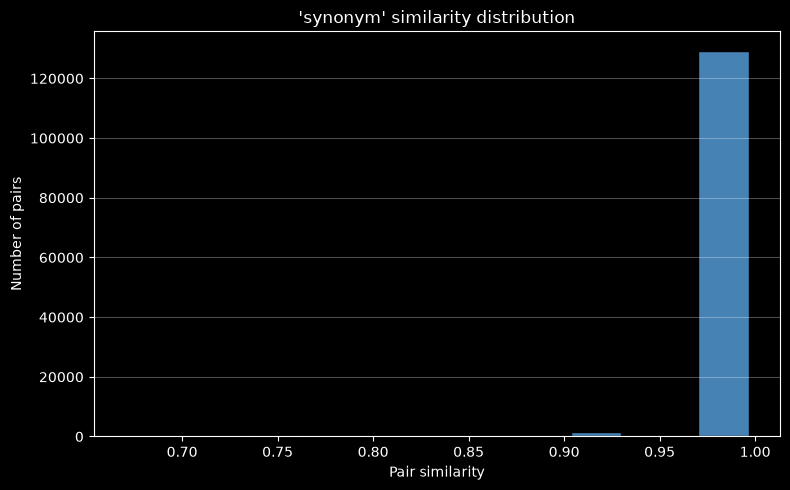

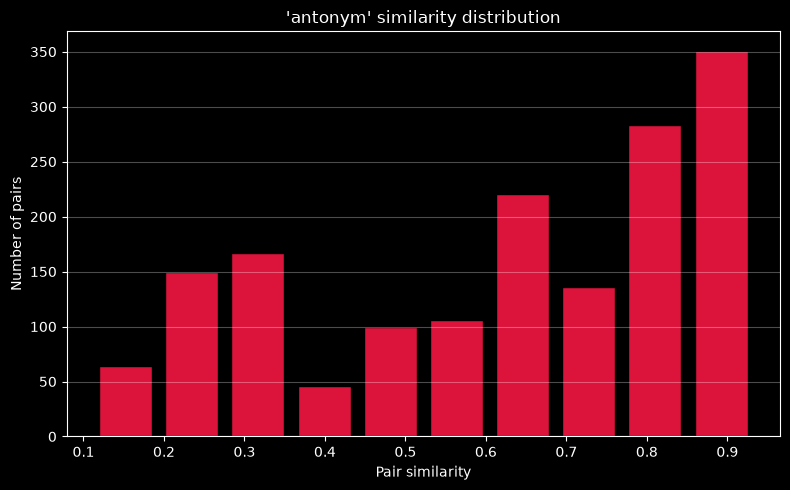

In [3]:
BIN_COUNT = 10
COLORS = ["steelblue", "crimson"]

for i, relation in enumerate(["synonym", "antonym"]):
    sims = DATAFRAME.loc[DATAFRAME["relation"] == relation, "similarity"].dropna()

    min_sim = sims.min()
    max_sim = sims.max()

    bins = np.linspace(min_sim, max_sim, BIN_COUNT + 1)

    plt.figure(figsize=(8,5))
    plt.hist(sims, bins=bins, edgecolor="black", rwidth=0.8, color=COLORS[i % len(COLORS)])
    plt.xlabel("Pair similarity")
    plt.ylabel("Number of pairs")
    plt.title(f"{relation!r} similarity distribution")
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()
    print()

[Some yapping about result]

 ## 3. Difference between semantic similarity can be used distinguish between synonymy and antonymy
"Validating your answer using statistical hypothesis testing"

In [4]:
# Reserved for possible code for 3.
pass

## 4. Transitivity relationships in synonyms and antonyms

108545
89513 1921
25125
9096 875


,pos,relation,total,successful,percentage
0,Noun,Synonyms,367083,257613,70.178407
1,Noun,Antonyms,67,20,29.850746
2,Verb,Synonyms,233414,110223,47.222103
3,Verb,Antonyms,91,21,23.076923


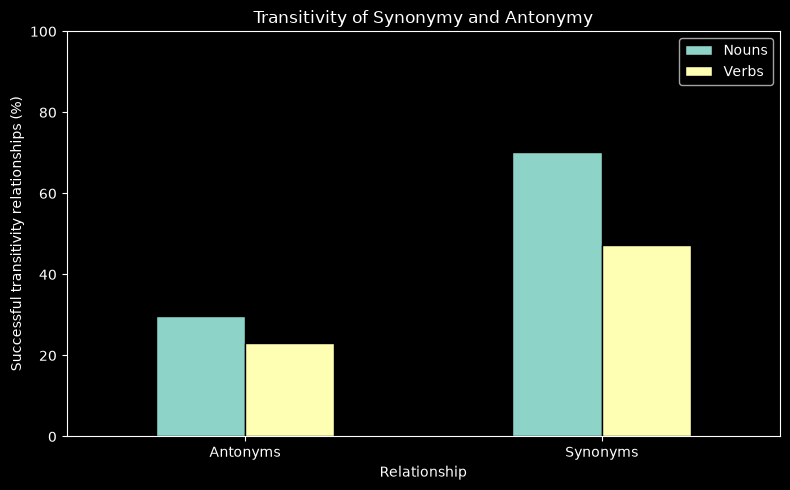

In [10]:
def build_relations_tables(df_pos):
    synonyms = defaultdict(set)
    antonyms = defaultdict(set)

    print(len(df_pos))
    for row in df_pos.itertuples(index=False):
        table = synonyms if row.relation == "synonym" else antonyms
        table[row.word1].add(row.word2)
        table[row.word2].add(row.word1)

    print(len(synonyms), len(antonyms))
    return synonyms, antonyms


def get_transitivity_relationships(relations, synonyms):
    count = 0
    success = 0

    for y, neighbor in relations.items():
        for x, z in combinations(neighbor, 2):
            count += 1
            if z in synonyms.get(x, set()):
                success += 1

    return count, success


results = []

for pos in ["n", "v"]:
    df_pos = DATAFRAME[DATAFRAME["pos"] == pos]

    synonyms, antonyms = build_relations_tables(df_pos)

    for relation, relations in [("Synonyms", synonyms), ("Antonyms", antonyms)]:
        total, successful = get_transitivity_relationships(relations, synonyms)
        percentage = (successful / total) * 100 if total > 0 else 0

        results.append({
            'pos': "Noun" if pos == "n" else "Verb",
            'relation': relation,
            'total': total,
            'successful': successful,
            'percentage': percentage
        })

df_transitivity = pd.DataFrame(results)
display(df_transitivity)

ax = df_transitivity.pivot(
    index="relation",
    columns="pos",
    values="percentage"
).plot.bar(figsize=(8,5), edgecolor="black", rot=0)
ax.set_title("Transitivity of Synonymy and Antonymy")
ax.set_xlabel("Relationship")
ax.set_ylabel("Successful transitivity relationships (%)")
ax.set_ylim(0, 100)
ax.legend(["Nouns", "Verbs"])
plt.tight_layout()
plt.show()

[Some yapping about results]

## 5. Hypernymy, testing if synonyms have same root node.